In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adagrad
from tensorflow.keras.layers import Dense

import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_diabetes
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

In [18]:
X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler_x = StandardScaler()
X_train_s = scaler_x.fit_transform(X_train)
X_test_s = scaler_x.transform(X_test)

scaler_y = StandardScaler()
y_train_s = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()

In [19]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_preds = rf.predict(X_test)

In [20]:
model = Sequential([Dense(1, input_shape=(X_train.shape[1],))])
model.compile(optimizer=Adagrad(learning_rate=5.0), loss='mse')
model.fit(X_train_s, y_train, epochs=100, batch_size=32, verbose=0)

c:\Users\VICTUS\Desktop\مواد\الفصل الاول\ML\ML-ASS\venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [21]:
lin_preds = model.predict(X_test_s, verbose=0).flatten()


In [22]:

voting_preds = (rf_preds + lin_preds) / 2
print(f"Voting Accuracy (Adagrad): {r2_score(y_test, voting_preds) * 100:.2f}%")

Voting Accuracy (Adagrad): 47.29%


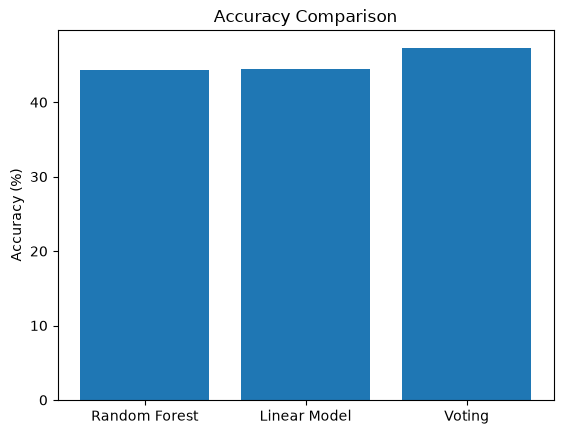

In [23]:

rf_acc = r2_score(y_test, rf_preds) * 100
lin_acc = r2_score(y_test, lin_preds) * 100
vot_acc = r2_score(y_test, voting_preds) * 100

# الرسم البسيط
plt.bar(["Random Forest", "Linear Model", "Voting"], [rf_acc, lin_acc, vot_acc])
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy (%)")
plt.show()